In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")


sns.set_theme(style="whitegrid")

In [18]:
df = pd.read_csv("house_price_prediction_500_rows.csv")

df.head()

,area_sqft,bedrooms,bathrooms,stories,parking,age_years,location_score,furnished,property_type,distance_to_city_km,price_lakh
0,3674,5,5,2,0,18,6.3,Unfurnished,Independent House,14.0,319.28
1,1360,2,2,2,2,28,6.8,Furnished,Independent House,5.4,187.89
2,1794,4,5,4,0,26,6.9,Unfurnished,Apartment,3.9,190.02
3,1630,3,3,2,2,28,5.0,Semi-Furnished,Apartment,7.5,188.37
4,1595,3,3,2,1,1,9.2,Semi-Furnished,Independent House,9.1,234.33


In [19]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 500
Number of Columns: 11


In [4]:
df.isnull().sum()

area_sqft              0
bedrooms               0
bathrooms              0
stories                0
parking                0
age_years              0
location_score         0
furnished              0
property_type          0
distance_to_city_km    0
price_lakh             0
dtype: int64

In [20]:
df.describe()

,area_sqft,bedrooms,bathrooms,stories,parking,age_years,location_score,distance_to_city_km,price_lakh
count,500.00000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2319.38400,3.580000,3.358000,2.192000,1.176000,15.198000,6.523400,9.021800,256.466200
std,1003.67328,1.677268,1.471791,0.936424,1.080444,8.989573,1.718517,4.627978,81.742121
min,501.00000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,69.540000
25%,1478.75000,2.000000,2.000000,1.000000,0.000000,7.000000,5.300000,5.800000,194.047500
50%,2297.50000,4.000000,3.000000,2.000000,1.000000,16.000000,6.550000,8.500000,252.230000
75%,3208.00000,5.000000,5.000000,3.000000,2.000000,23.000000,7.725000,12.225000,320.670000
max,3999.00000,6.000000,5.000000,4.000000,4.000000,30.000000,10.000000,22.200000,430.350000


In [6]:
X = df.drop("price_lakh", axis=1)
y = df["price_lakh"]

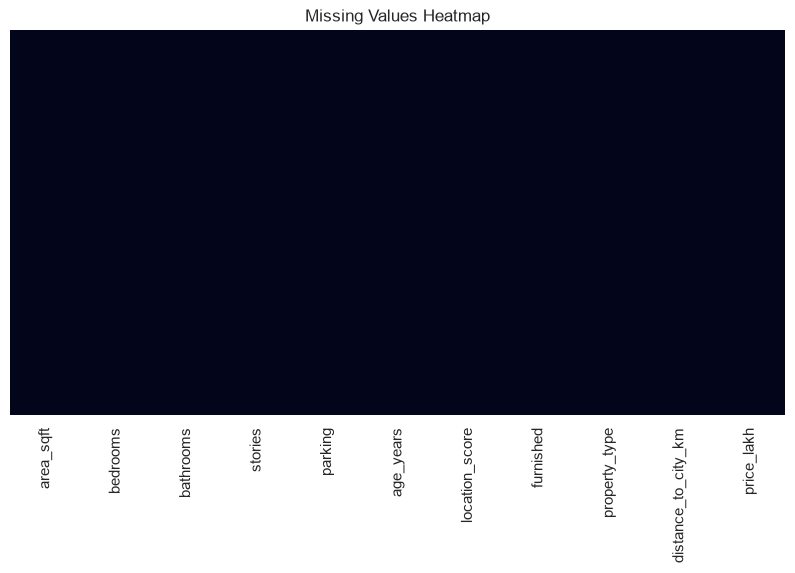

In [21]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Heatmap")
plt.show()

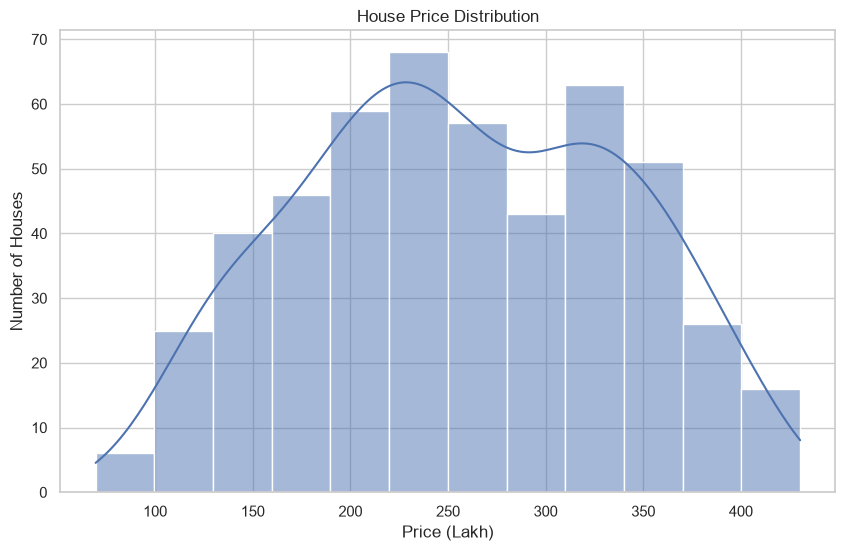

In [22]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["price_lakh"],
    kde=True
)

plt.title("House Price Distribution")
plt.xlabel("Price (Lakh)")
plt.ylabel("Number of Houses")

plt.show()

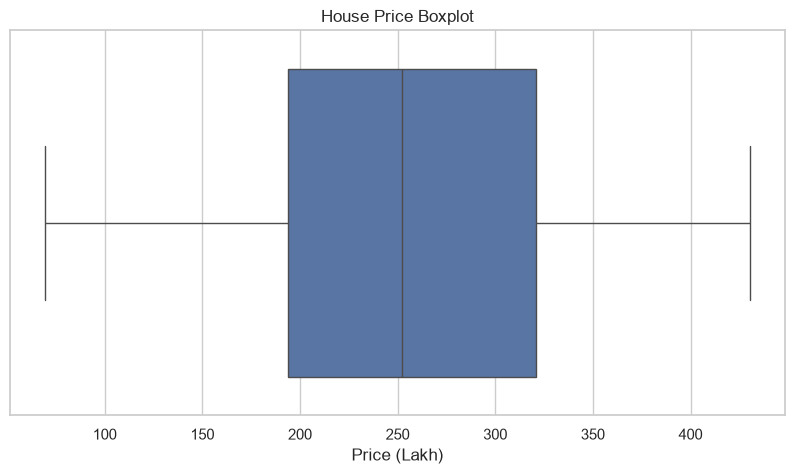

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["price_lakh"]
)

plt.title("House Price Boxplot")
plt.xlabel("Price (Lakh)")

plt.show()

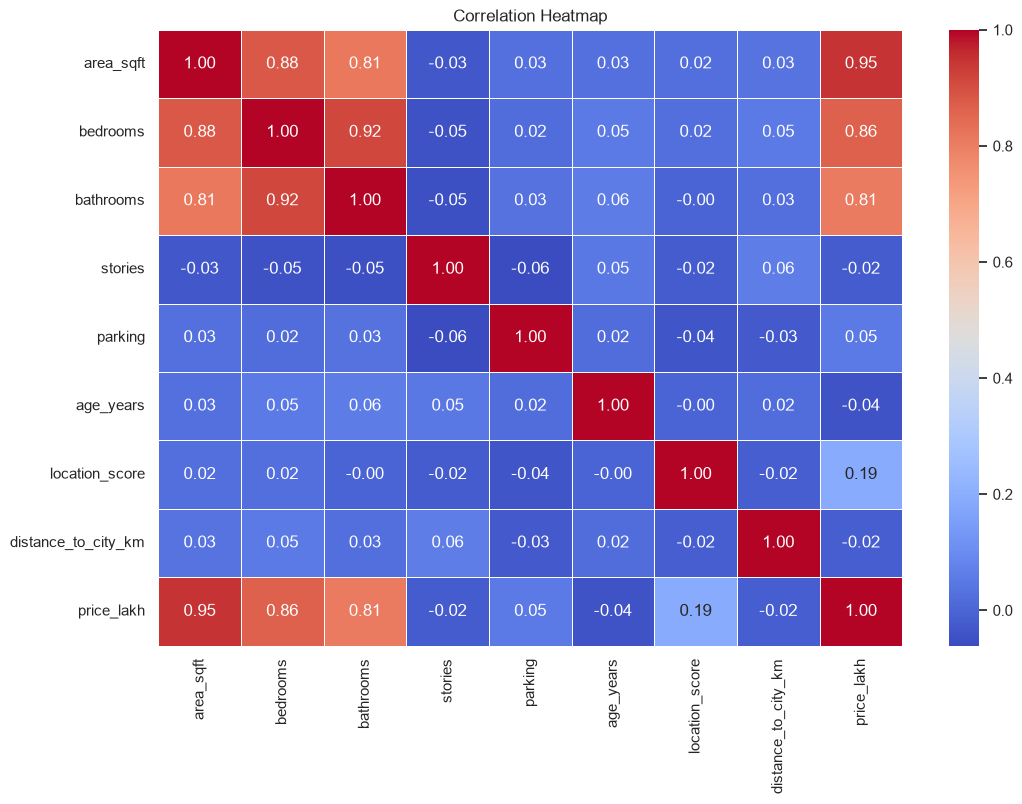

In [24]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

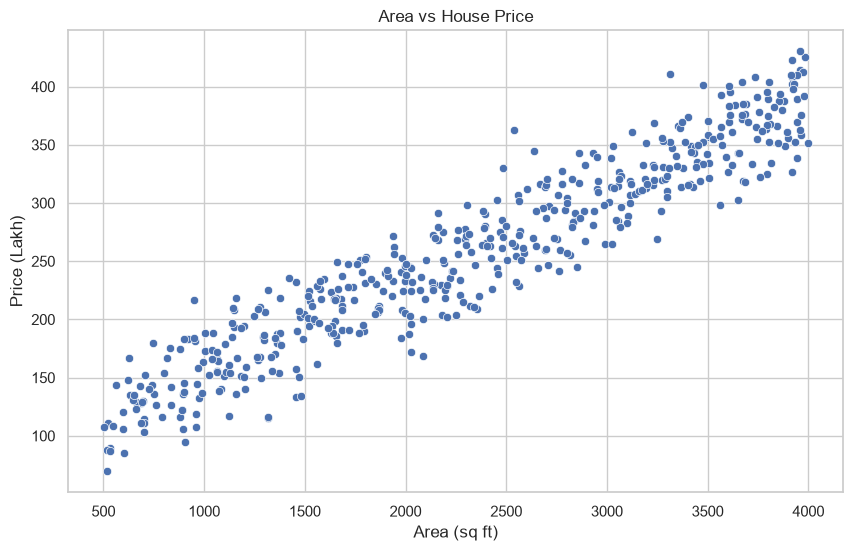

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="area_sqft",
    y="price_lakh"
)

plt.title("Area vs House Price")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (Lakh)")

plt.show()

In [ ]:
categorical_features = [
    "furnished",
    "property_type"
]

numeric_features = [
    "area_sqft",
    "bedrooms",
    "bathrooms",
    "stories",
    "parking",
    "age_years",
    "location_score",
    "distance_to_city_km"
]

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 10)
Testing data: (100, 10)


In [10]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['area_sqft','bedrooms','bathrooms',...,'furnished','property_type', 'distance_to_city_km']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This

In [11]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[331.35920954 303.77807776 188.38921797 314.40273704 193.88752247
 263.23447991 200.759395   228.68322781 316.41998466 228.31142892]


In [12]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE : 13.379347813930112
MSE : 257.4758229776426
RMSE: 16.04605319004155
R² Score: 0.957223782139643


In [13]:
new_house = pd.DataFrame({
    "area_sqft": [2000],
    "bedrooms": [3],
    "bathrooms": [3],
    "stories": [2],
    "parking": [2],
    "age_years": [5],
    "location_score": [8.5],
    "furnished": ["Furnished"],
    "property_type": ["Independent House"],
    "distance_to_city_km": [6]
})

predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0], "Lakh")

Predicted House Price: 269.9010427942742 Lakh


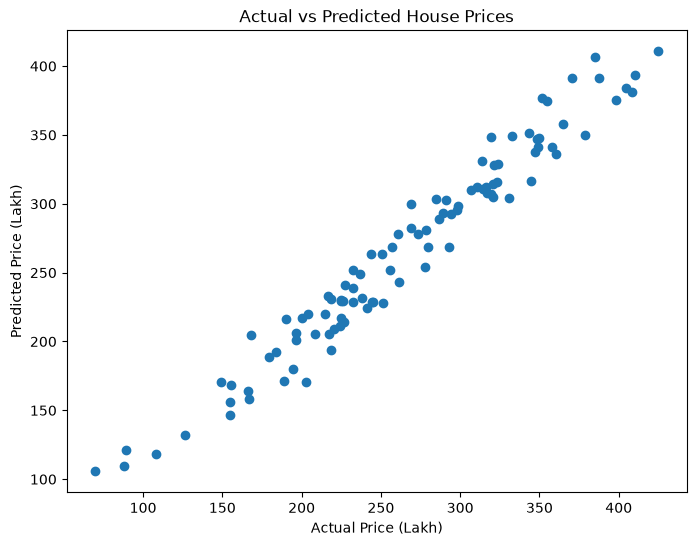

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price (Lakh)")
plt.ylabel("Predicted Price (Lakh)")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [15]:
new_houses = pd.DataFrame({
    "area_sqft": [1000, 1500, 2000],
    "bedrooms": [2, 3, 4],
    "bathrooms": [2, 2, 3],
    "stories": [1, 2, 2],
    "parking": [1, 1, 2],
    "age_years": [5, 10, 3],
    "location_score": [7.5, 8.0, 9.0],
    "furnished": [
        "Semi-Furnished",
        "Furnished",
        "Furnished"
    ],
    "property_type": [
        "Apartment",
        "Independent House",
        "Villa"
    ],
    "distance_to_city_km": [8, 6, 4]
})

predictions = model.predict(new_houses)

for i, price in enumerate(predictions):
    print(f"House {i+1}: ₹{price:.2f} Lakh")

House 1: ₹158.36 Lakh
House 2: ₹222.95 Lakh
House 3: ₹302.39 Lakh


In [16]:
import joblib

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!
